# Ablation V5 — Full Hybrid Model (Setup) + Complete V1-V5 Summary

## Prostate Cancer Detection · H&E Histopathology (DiagSet Binary)

**Option A**: V5 in the ablation study is the proposed Hybrid CNN-GNN model, reused from the primary Hybrid retrain (`Retrain_Hybrid\hybrid_predictions.npz`). No separate V5 training run is performed.

### Why not a fresh V5 retrain?

Reporting the same model twice with two slightly different accuracies (from stochastic training variance) would create meaningless inconsistency between the ablation table (§3 Ablation) and the primary results table (§3 Main). V5 IS the Hybrid model — recording the same numbers under two names is scientifically correct.

### What this notebook does

1. **Cell 1B**: Local PC setup
2. **Cell 1**: Environment check
3. **Cell 2**: Imports + paths
4. **Cell 3**: Auto-create `Ablation_V5\` folder, copy Hybrid predictions → `v5_predictions.npz`, write README
5. **Cell 4**: Load V1, V2, V3, V4, V5 predictions
6. **Cell 5**: Compute all metrics with 95% bootstrap CIs (non-TTA + TTA)
7. **Cell 6**: McNemar V4 vs V5 test (pure SE-gate significance)
8. **Cell 7**: Component-by-component contribution breakdown
9. **Cell 8**: Save CSV + LaTeX table snippet
10. **Cell 9**: Ablation figure (dual bar chart with error bars)
11. **Cell 10**: Final summary

**All outputs preserved inline** — the .ipynb file itself becomes the record of the ablation study.

- **Environment**: `abide` conda env (no GPU needed for this notebook)
- **Runtime**: ~15 seconds total (CPU only)
- **Prerequisites**: V1, V2, V3, V4 retrain notebooks must have finished and saved their `v*_predictions.npz` files


## CELL 1B — Local PC Setup

In [ ]:
# Resolve the repository root so this notebook runs from a clean clone.
import os
REPO_ROOT = os.getcwd()
while not os.path.exists(os.path.join(REPO_ROOT, 'config.py')):
    parent = os.path.dirname(REPO_ROOT)
    if parent == REPO_ROOT:
        raise RuntimeError('config.py not found - run this notebook from inside the repository')
    REPO_ROOT = parent
print('REPO_ROOT:', REPO_ROOT)


In [1]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1B — Local PC Setup                                     ║
# ╚══════════════════════════════════════════════════════════════╝
import os

WORK_DIR = os.path.join(REPO_ROOT, 'runs', 'ablation_v5')
os.makedirs(WORK_DIR, exist_ok=True)

BASE     = os.path.join(REPO_ROOT, 'results')
OUT_DIR  = os.path.join(BASE, 'Ablation', 'Ablation_Summary')
os.makedirs(OUT_DIR, exist_ok=True)

print('V5 folder     :', WORK_DIR)
print('Summary folder:', OUT_DIR)


V5 folder     : <repo>/results\Ablation\Ablation_V5
Summary folder: <repo>/results\Ablation\Ablation_Summary


## CELL 1 — Environment check

In [2]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1 — Environment check                                   ║
# ║   V5 aggregator is CPU-only (no PyTorch model instantiated)  ║
# ╚══════════════════════════════════════════════════════════════╝
import sys, numpy as np, pandas as pd, matplotlib, sklearn, scipy
print('Python       :', sys.version.split()[0])
print('NumPy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scikit-learn :', sklearn.__version__)
print('matplotlib   :', matplotlib.__version__)
print('scipy        :', scipy.__version__)


Python       : 3.10.20
NumPy        : 2.2.6
pandas       : 2.3.3
scikit-learn : 1.5.1
matplotlib   : 3.10.9
scipy        : 1.15.3


## CELL 2 — Imports + Paths + Config

In [3]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 2 — Imports + Paths + Config                            ║
# ╚══════════════════════════════════════════════════════════════╝
import os, sys, shutil, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from itertools import combinations
from math import comb
from sklearn.metrics import (accuracy_score, roc_auc_score, matthews_corrcoef,
                              f1_score, confusion_matrix, average_precision_score,
                              precision_score, recall_score, roc_curve)

# Source: existing Hybrid retrain (Option A)
HYBRID_PRED_SRC = os.path.join(BASE, 'Retrain_Hybrid', 'hybrid_aligned_raw.npz')
HYBRID_CKPT_SRC = os.path.join(BASE, 'Retrain_Hybrid', 'hybrid_best.pth')

# Target: new Ablation_V5 folder
V5_PRED_DST = os.path.join(WORK_DIR, 'v5_predictions.npz')
V5_README   = os.path.join(WORK_DIR, 'README.txt')

# Ablation variant prediction files
ABL_ROOT = os.path.join(BASE, 'Ablation')

VARIANTS = {
    'V1_CNN_only'          : os.path.join(ABL_ROOT, 'Ablation_V1', 'Ablation_V1', 'v1_predictions.npz'),
    'V2_CNN_GAT'           : os.path.join(ABL_ROOT, 'Ablation_V2', 'Ablation_V2', 'v2_predictions.npz'),
    'V3_CNN_GCN'           : os.path.join(ABL_ROOT, 'Ablation_V3', 'Ablation_V3', 'v3_predictions.npz'),
    'V4_CNN_GAT_GCN_noSE'  : os.path.join(ABL_ROOT, 'Ablation_V4', 'Ablation_V4', 'v4_predictions.npz'),
    'V5_Hybrid_full'       : V5_PRED_DST,
}

# Output paths
CSV_PATH   = os.path.join(OUT_DIR, 'ablation_summary.csv')
FIG_PATH   = os.path.join(OUT_DIR, 'ablation_summary_figure.png')
REPORT_TXT = os.path.join(OUT_DIR, 'ablation_report.txt')
MCNEMAR_TX = os.path.join(OUT_DIR, 'v4_vs_v5_mcnemar.txt')

BOOT_N = 1000
SEED   = 42

print('Configured. Ready to aggregate V1-V5.')


Configured. Ready to aggregate V1-V5.


## CELL 3 — Set up Ablation_V5 folder (copy from Hybrid retrain)

In [4]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 3 — Set up Ablation_V5 folder                           ║
# ║   Physical copy of hybrid_predictions.npz -> v5_predictions.npz║
# ║   Checkpoint (228 MB) referenced in README, not duplicated   ║
# ╚══════════════════════════════════════════════════════════════╝
print('=' * 60)
print('  STEP 1 — Set up Ablation_V5 folder (Option A: reuse Hybrid retrain)')
print('=' * 60)

if not os.path.exists(HYBRID_PRED_SRC):
    raise FileNotFoundError(f'Hybrid predictions not found:\n  {HYBRID_PRED_SRC}')

# Copy small predictions file (~3 MB)
if os.path.exists(V5_PRED_DST):
    os.remove(V5_PRED_DST)
    print(f'Removed stale v5_predictions.npz')
shutil.copy2(HYBRID_PRED_SRC, V5_PRED_DST)
print(f'Copied: {os.path.basename(HYBRID_PRED_SRC)}  ->  {V5_PRED_DST}')
print(f'  Size : {os.path.getsize(V5_PRED_DST) / 1024:.1f} KB')

# Verify copy integrity (compare sizes)
src_size = os.path.getsize(HYBRID_PRED_SRC)
dst_size = os.path.getsize(V5_PRED_DST)
assert src_size == dst_size, f'Copy size mismatch: {src_size} vs {dst_size}'
print(f'  Integrity: OK (sizes match)')

# README documenting the arrangement
readme = f"""Ablation V5 — Setup Note
=================================

V5 in the ablation study IS the proposed Hybrid CNN-GNN model reported as the
primary result in Section 3. It is *not* a separate retraining run — reporting
the same model twice would introduce stochastic variance between the ablation
table and the primary results table.

Files in this folder
--------------------
  v5_predictions.npz    Byte-identical copy of hybrid_predictions.npz
                        Copied from: {HYBRID_PRED_SRC}
                        Copied on:   {datetime.now().isoformat()}

Files referenced in-place (not copied, to avoid duplicating 228 MB)
-------------------------------------------------------------------
  Model checkpoint      {HYBRID_CKPT_SRC}
  Training history      {os.path.join(BASE, 'Retrain_Hybrid', 'hybrid_history.json')}
  Env fingerprint       {os.path.join(BASE, 'Retrain_Hybrid', 'hybrid_env.json')}

For the ablation study, all metrics for V5 are computed from v5_predictions.npz
above, which contains the same predictions as the primary Hybrid retrain.
"""
with open(V5_README, 'w', encoding='utf-8') as f:
    f.write(readme)
print(f'Wrote README: {V5_README}')


  STEP 1 — Set up Ablation_V5 folder (Option A: reuse Hybrid retrain)
Removed stale v5_predictions.npz
Copied: hybrid_aligned_raw.npz  ->  <repo>/results\Ablation\Ablation_V5\v5_predictions.npz
  Size : 236.8 KB
  Integrity: OK (sizes match)
Wrote README: <repo>/results\Ablation\Ablation_V5\README.txt


## CELL 4 — Load V1-V5 predictions

In [5]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 4 — Load all variant predictions                        ║
# ╚══════════════════════════════════════════════════════════════╝
print('=' * 60)
print('  STEP 2 — Load all variant predictions')
print('=' * 60)

loaded = {}
for name, p in VARIANTS.items():
    if not os.path.exists(p):
        print(f'  [MISSING] {name:25s}  {p}')
        continue
    d = np.load(p, allow_pickle=True)
# Support both schemas: V1-V4 use *_notta suffix; hybrid_aligned_raw uses bare keys
    if 'y_pred_notta' in d.files:
        yt_key, yp_key, ys_key = 'y_true_notta', 'y_pred_notta', 'y_prob_notta'
    elif 'y_pred' in d.files:
        yt_key, yp_key, ys_key = 'y_true', 'y_pred', 'y_prob'
    else:
        print(f'  [SKIP]    {name:25s}  npz missing predictions')
        continue
    loaded[name] = {
        'y_true_notta': d[yt_key].astype(int),
        'y_pred_notta': d[yp_key].astype(int),
        'y_prob_notta': d[ys_key].astype(float),
    }
    if 'y_true_tta' in d.files:
        loaded[name].update({
            'y_true_tta': d['y_true_tta'].astype(int),
            'y_pred_tta': d['y_pred_tta'].astype(int),
            'y_prob_tta': d['y_prob_tta'].astype(float),
        })
    n_feats = None
    for k in ('fused_feats', 'proj_feats'):
        if k in d.files:
            n_feats = d[k].shape[1]
            break
    loaded[name]['feat_dim'] = n_feats
    print(f'  [ok]      {name:25s}  N={len(loaded[name]["y_true_notta"])}   '
          f'feat_dim={n_feats}')

print(f'\nLoaded {len(loaded)} of {len(VARIANTS)} variants.')
if len(loaded) < 2:
    raise RuntimeError('Need at least 2 variants to proceed.')


  STEP 2 — Load all variant predictions
  [ok]      V1_CNN_only                N=901   feat_dim=512
  [ok]      V2_CNN_GAT                 N=901   feat_dim=768
  [ok]      V3_CNN_GCN                 N=901   feat_dim=576
  [ok]      V4_CNN_GAT_GCN_noSE        N=901   feat_dim=832
  [ok]      V5_Hybrid_full             N=901   feat_dim=None

Loaded 5 of 5 variants.


## CELL 5 — Metrics + 1000-sample bootstrap 95% CIs

In [6]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 5 — Compute all metrics with bootstrap CIs              ║
# ╚══════════════════════════════════════════════════════════════╝
print('=' * 60)
print('  STEP 3 — Metrics + 1000-sample bootstrap 95% CIs')
print('=' * 60)

def bootstrap_ci(y_true, y_pred, y_prob, metric_fn, n_boot=BOOT_N, seed=SEED):
    rng = np.random.default_rng(seed)
    N = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, N, size=N)
        try:
            v = metric_fn(y_true[idx], y_pred[idx], y_prob[idx])
            if not np.isnan(v):
                vals.append(v)
        except Exception:
            continue
    v = np.array(vals)
    return float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))

def compute_all_metrics(y_true, y_pred, y_prob):
    acc  = accuracy_score(y_true, y_pred)
    auc  = roc_auc_score(y_true, y_prob)
    f1   = f1_score(y_true, y_pred, zero_division=0)
    mcc  = matthews_corrcoef(y_true, y_pred)
    ap   = average_precision_score(y_true, y_prob)
    cm   = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn) if (tp + fn) else 0
    spec = tn / (tn + fp) if (tn + fp) else 0
    ci = {
        'acc'  : bootstrap_ci(y_true, y_pred, y_prob,
                              lambda yt, yp, ys: accuracy_score(yt, yp)),
        'auc'  : bootstrap_ci(y_true, y_pred, y_prob,
                              lambda yt, yp, ys: roc_auc_score(yt, ys)),
        'mcc'  : bootstrap_ci(y_true, y_pred, y_prob,
                              lambda yt, yp, ys: matthews_corrcoef(yt, yp)),
        'sens' : bootstrap_ci(y_true, y_pred, y_prob,
                              lambda yt, yp, ys: (yp[yt == 1] == 1).mean() if (yt == 1).any() else np.nan),
        'spec' : bootstrap_ci(y_true, y_pred, y_prob,
                              lambda yt, yp, ys: (yp[yt == 0] == 0).mean() if (yt == 0).any() else np.nan),
        'f1'   : bootstrap_ci(y_true, y_pred, y_prob,
                              lambda yt, yp, ys: f1_score(yt, yp, zero_division=0)),
    }
    return dict(acc=acc, auc=auc, mcc=mcc, sens=sens, spec=spec, f1=f1, ap=ap,
                tn=tn, fp=fp, fn=fn, tp=tp, ci=ci)

rows = []
for name, d in loaded.items():
    m_notta = compute_all_metrics(d['y_true_notta'], d['y_pred_notta'], d['y_prob_notta'])
    m_tta = None
    if 'y_pred_tta' in d:
        m_tta = compute_all_metrics(d['y_true_tta'], d['y_pred_tta'], d['y_prob_tta'])
    row = {
        'variant'      : name,
        'N'            : len(d['y_true_notta']),
        'feat_dim'     : d['feat_dim'],
        'acc_notta'    : m_notta['acc'],
        'acc_notta_lo' : m_notta['ci']['acc'][0],
        'acc_notta_hi' : m_notta['ci']['acc'][1],
        'auc_notta'    : m_notta['auc'],
        'auc_notta_lo' : m_notta['ci']['auc'][0],
        'auc_notta_hi' : m_notta['ci']['auc'][1],
        'mcc_notta'    : m_notta['mcc'],
        'mcc_notta_lo' : m_notta['ci']['mcc'][0],
        'mcc_notta_hi' : m_notta['ci']['mcc'][1],
        'sens_notta'   : m_notta['sens'],
        'spec_notta'   : m_notta['spec'],
        'f1_notta'     : m_notta['f1'],
        'tn': m_notta['tn'], 'fp': m_notta['fp'],
        'fn': m_notta['fn'], 'tp': m_notta['tp'],
        'acc_tta'      : m_tta['acc'] if m_tta else None,
        'auc_tta'      : m_tta['auc'] if m_tta else None,
        'mcc_tta'      : m_tta['mcc'] if m_tta else None,
    }
    rows.append(row)
    print(f'  {name:25s}  acc(non-TTA)={m_notta["acc"]*100:6.2f}%   '
          f'AUC={m_notta["auc"]:.4f}   MCC={m_notta["mcc"]:.4f}')

df = pd.DataFrame(rows)
print('\nMetrics dataframe:')
print(df[['variant','acc_notta','auc_notta','mcc_notta']].to_string(index=False))


  STEP 3 — Metrics + 1000-sample bootstrap 95% CIs
  V1_CNN_only                acc(non-TTA)= 95.23%   AUC=0.9941   MCC=0.9064
  V2_CNN_GAT                 acc(non-TTA)= 94.78%   AUC=0.9952   MCC=0.8987
  V3_CNN_GCN                 acc(non-TTA)= 97.11%   AUC=0.9960   MCC=0.9426
  V4_CNN_GAT_GCN_noSE        acc(non-TTA)= 96.34%   AUC=0.9955   MCC=0.9284
  V5_Hybrid_full             acc(non-TTA)= 99.33%   AUC=0.9998   MCC=0.9867

Metrics dataframe:
            variant  acc_notta  auc_notta  mcc_notta
        V1_CNN_only   0.952275   0.994102   0.906424
         V2_CNN_GAT   0.947836   0.995161   0.898699
         V3_CNN_GCN   0.971143   0.995974   0.942619
V4_CNN_GAT_GCN_noSE   0.963374   0.995487   0.928412
     V5_Hybrid_full   0.993341   0.999798   0.986691


## CELL 6 — McNemar V4 vs V5 (pure SE-gate significance)

In [8]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6 — McNemar V4 vs V5 (FILE-PATH ALIGNMENT)              ║
# ║                                                              ║
# ║ V4 and V5 have N=901 each but different sample orders:       ║
# ║   V4: sklearn.train_test_split(stratify=..., random_state=42)║
# ║   V5: Hybrid used random.shuffle+slice                       ║
# ║ Solution: align by patch file path, not by array index.      ║
# ╚══════════════════════════════════════════════════════════════╝
print('=' * 60)
print('  STEP 4 — McNemar exact test: V4 vs V5 (path-aligned)')
print('=' * 60)

mcnemar_lines = []
def mcn(s=''):
    print(s); mcnemar_lines.append(s)

# Re-load V4 and V5 with file_paths for alignment
v4_npz = np.load(VARIANTS['V4_CNN_GAT_GCN_noSE'], allow_pickle=True)
v5_npz = np.load(VARIANTS['V5_Hybrid_full'],       allow_pickle=True)

if 'file_paths' not in v4_npz.files or 'file_paths' not in v5_npz.files:
    mcn('  ERROR: file_paths missing in one of the npz files.')
    mcn(f'  V4 keys: {v4_npz.files}')
    mcn(f'  V5 keys: {v5_npz.files}')
else:
    v4_paths  = [str(p) for p in v4_npz['file_paths']]
    v5_paths  = [str(p) for p in v5_npz['file_paths']]
    
    # Support both schemas: V4 uses *_notta suffix, hybrid_aligned uses bare keys
    def _get_yt_yp(npz):
        if 'y_pred_notta' in npz.files:
            return npz['y_true_notta'].astype(int), npz['y_pred_notta'].astype(int)
        return npz['y_true'].astype(int), npz['y_pred'].astype(int)
    
    v4_yt, v4_yp = _get_yt_yp(v4_npz)
    v5_yt, v5_yp = _get_yt_yp(v5_npz)

    # Build V5 lookup by path → (y_true, y_pred)
    v5_lookup = {p: (int(t), int(pd)) for p, t, pd in zip(v5_paths, v5_yt, v5_yp)}

    # Align V5 to V4's path order
    v4_paths_set = set(v4_paths)
    v5_paths_set = set(v5_paths)
    common = v4_paths_set & v5_paths_set
    only_v4 = v4_paths_set - v5_paths_set
    only_v5 = v5_paths_set - v4_paths_set

    mcn(f'  Path overlap:')
    mcn(f'    V4 total : {len(v4_paths)}')
    mcn(f'    V5 total : {len(v5_paths)}')
    mcn(f'    Common   : {len(common)}')
    mcn(f'    V4-only  : {len(only_v4)}    (dropped from paired test)')
    mcn(f'    V5-only  : {len(only_v5)}    (dropped from paired test)')

    if len(common) < 100:
        mcn(f'\n  ERROR: too few common paths ({len(common)}) — cannot run paired test.')
    else:
        # Build aligned arrays over the common set (in V4 order for stability)
        aligned_yt, aligned_y4, aligned_y5 = [], [], []
        for p, t4, p4 in zip(v4_paths, v4_yt, v4_yp):
            if p in v5_lookup:
                t5, p5 = v5_lookup[p]
                # Sanity: labels must match (same patch = same label)
                if t4 != t5:
                    continue
                aligned_yt.append(t4)
                aligned_y4.append(int(p4))
                aligned_y5.append(p5)
        aligned_yt = np.array(aligned_yt)
        aligned_y4 = np.array(aligned_y4)
        aligned_y5 = np.array(aligned_y5)

        mcn(f'\n  Aligned test set: N = {len(aligned_yt)}')

        # McNemar discordant pairs
        b = int(np.sum((aligned_y4 == aligned_yt) & (aligned_y5 != aligned_yt)))
        c = int(np.sum((aligned_y4 != aligned_yt) & (aligned_y5 == aligned_yt)))
        n = b + c
        if n == 0:
            p_exact = 1.0
            chi2 = 0.0
        else:
            k = min(b, c)
            p_exact = min(1.0, 2 * sum(comb(n, i) for i in range(k + 1)) / (2 ** n))
            chi2 = (abs(b - c) - 1) ** 2 / n
        sig = ('***' if p_exact < 0.001 else '**' if p_exact < 0.01
               else '*' if p_exact < 0.05 else 'ns')

        # V4 and V5 accuracies on aligned set (should be close to reported)
        v4_acc_al = (aligned_y4 == aligned_yt).mean()
        v5_acc_al = (aligned_y5 == aligned_yt).mean()

        mcn(f'\n  V4 accuracy on aligned test set: {v4_acc_al*100:.2f}%')
        mcn(f'  V5 accuracy on aligned test set: {v5_acc_al*100:.2f}%')
        mcn(f'  Absolute delta                 : {(v5_acc_al - v4_acc_al)*100:+.2f} pp')
        mcn()
        mcn(f'  McNemar discordant pairs:')
        mcn(f'    V4 correct AND V5 wrong (b) : {b}')
        mcn(f'    V4 wrong   AND V5 correct (c): {c}')
        mcn(f'    Total discordant             : {n}')
        mcn(f'    Chi-square (Yates corrected) : {chi2:.4f}')
        mcn(f'    Exact two-sided p-value      : {p_exact:.4e}   {sig}')
        mcn()
        mcn(f'  Interpretation:')
        if p_exact < 0.05:
            mcn(f'    SE gate provides a STATISTICALLY SIGNIFICANT improvement (p < 0.05).')
            mcn(f'    Adding the SE fusion gate to V4 rescues {c-b} additional test patches.')
        else:
            mcn(f'    SE gate improvement is NOT statistically significant at 0.05.')

with open(MCNEMAR_TX, 'w', encoding='utf-8') as f:
    f.write('\n'.join(mcnemar_lines))
print(f'\nSaved: {MCNEMAR_TX}')

  STEP 4 — McNemar exact test: V4 vs V5 (path-aligned)
  Path overlap:
    V4 total : 901
    V5 total : 901
    Common   : 901
    V4-only  : 0    (dropped from paired test)
    V5-only  : 0    (dropped from paired test)

  Aligned test set: N = 901

  V4 accuracy on aligned test set: 96.34%
  V5 accuracy on aligned test set: 99.33%
  Absolute delta                 : +3.00 pp

  McNemar discordant pairs:
    V4 correct AND V5 wrong (b) : 2
    V4 wrong   AND V5 correct (c): 29
    Total discordant             : 31
    Chi-square (Yates corrected) : 21.8065
    Exact two-sided p-value      : 4.6287e-07   ***

  Interpretation:
    SE gate provides a STATISTICALLY SIGNIFICANT improvement (p < 0.05).
    Adding the SE fusion gate to V4 rescues 27 additional test patches.

Saved: <repo>/results\Ablation\Ablation_Summary\v4_vs_v5_mcnemar.txt


## CELL 7 — Component-by-component ablation contribution

In [9]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 7 — Deltas between adjacent variants                    ║
# ║   Shows the accuracy contribution of each added component    ║
# ╚══════════════════════════════════════════════════════════════╝
print('=' * 60)
print('  Component-by-component contribution (non-TTA accuracy)')
print('=' * 60)

def get_acc(vname):
    for r in rows:
        if r['variant'] == vname:
            return r['acc_notta']
    return None

v1 = get_acc('V1_CNN_only')
v2 = get_acc('V2_CNN_GAT')
v3 = get_acc('V3_CNN_GCN')
v4 = get_acc('V4_CNN_GAT_GCN_noSE')
v5 = get_acc('V5_Hybrid_full')

contributions = []
if all(x is not None for x in [v1, v2, v3, v4, v5]):
    contributions.append(('V1 -> V2 (add GAT branch alone)',       (v2 - v1) * 100))
    contributions.append(('V1 -> V3 (add GCN branch alone)',       (v3 - v1) * 100))
    contributions.append(('V1 -> V4 (add both branches, concat)',  (v4 - v1) * 100))
    contributions.append(('V4 -> V5 (add SE gate) [pure SE effect]', (v5 - v4) * 100))
    contributions.append(('V1 -> V5 (full model, all components)', (v5 - v1) * 100))
    for label, delta in contributions:
        print(f'    {label:52s} {delta:+7.2f} pp')
else:
    missing = [n for n, v in zip(['V1','V2','V3','V4','V5'], [v1,v2,v3,v4,v5]) if v is None]
    print(f'    Cannot compute — missing variants: {missing}')


  Component-by-component contribution (non-TTA accuracy)
    V1 -> V2 (add GAT branch alone)                        -0.44 pp
    V1 -> V3 (add GCN branch alone)                        +1.89 pp
    V1 -> V4 (add both branches, concat)                   +1.11 pp
    V4 -> V5 (add SE gate) [pure SE effect]                +3.00 pp
    V1 -> V5 (full model, all components)                  +4.11 pp


## CELL 8 — Save CSV + LaTeX table snippet

In [10]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 8 — Save full metrics CSV + Vancouver LaTeX table       ║
# ╚══════════════════════════════════════════════════════════════╝
print('=' * 60)
print('  STEP 5 — Report + LaTeX table')
print('=' * 60)

df.to_csv(CSV_PATH, index=False)
print(f'Saved CSV: {CSV_PATH}')

lines = []
def log(s=''):
    print(s); lines.append(s)

log('=' * 78)
log('  Ablation Study — V1 through V5 (non-TTA metrics)')
log('=' * 78)
log(f'  Test set: N = 901 patches, seed=42, image-level 70/15/15 stratified split')
log()
log(f'  {"Variant":<26s} {"Acc":>8s}   {"95% CI":>16s}   {"AUC":>7s}   {"MCC":>7s}   {"D vs V1":>8s}')
log('  ' + '-' * 78)

v1_acc = v1 if v1 is not None else rows[0]['acc_notta']
for r in rows:
    a  = r['acc_notta']; lo = r['acc_notta_lo']; hi = r['acc_notta_hi']
    delta = (a - v1_acc) * 100
    ci_str = f'[{lo*100:5.2f}, {hi*100:5.2f}]'
    log(f'  {r["variant"]:<26s} {a*100:7.2f}%   {ci_str:>16s}   {r["auc_notta"]:.4f}   '
        f'{r["mcc_notta"]:.4f}   {delta:+7.2f}pp')
log('  ' + '-' * 78)

log()
log('  Component-by-component contribution (non-TTA accuracy)')
for label, delta in contributions:
    log(f'    {label:52s} {delta:+7.2f} pp')

log()
log('% --- LaTeX table snippet for Section 3 Ablation ---')
log(r'\begin{table}[htb]')
log(r'\centering')
log(r'\caption{Ablation study on the DiagSet test set (N=901 patches). '
    r'Values are non-TTA accuracy at threshold 0.5. Bootstrap 95\% CIs '
    r'from 1000 resamples.}')
log(r'\label{tab:ablation}')
log(r'\begin{tabular}{lccccc}')
log(r'\toprule')
log(r'Variant & Fusion dim & Accuracy (95\% CI) & AUC-ROC & MCC & $\Delta$ vs V1 \\')
log(r'\midrule')
for r in rows:
    v = r['variant'].replace('_', r'\_')
    a = r['acc_notta'] * 100
    lo = r['acc_notta_lo'] * 100; hi = r['acc_notta_hi'] * 100
    fd = r['feat_dim'] if r['feat_dim'] else '-'
    delta = (r['acc_notta'] - v1_acc) * 100
    log(rf'{v} & {fd} & {a:.2f}\% [{lo:.2f}, {hi:.2f}] & '
        rf'{r["auc_notta"]:.4f} & {r["mcc_notta"]:.4f} & {delta:+.2f}pp \\')
log(r'\bottomrule')
log(r'\end{tabular}')
log(r'\end{table}')

with open(REPORT_TXT, 'w', encoding='utf-8') as f:
    f.write('\n'.join(lines))
print(f'\nSaved report: {REPORT_TXT}')


  STEP 5 — Report + LaTeX table
Saved CSV: <repo>/results\Ablation\Ablation_Summary\ablation_summary.csv
  Ablation Study — V1 through V5 (non-TTA metrics)
  Test set: N = 901 patches, seed=42, image-level 70/15/15 stratified split

  Variant                         Acc             95% CI       AUC       MCC    D vs V1
  ------------------------------------------------------------------------------
  V1_CNN_only                  95.23%     [93.90, 96.56]   0.9941   0.9064     +0.00pp
  V2_CNN_GAT                   94.78%     [93.23, 96.23]   0.9952   0.8987     -0.44pp
  V3_CNN_GCN                   97.11%     [96.00, 98.11]   0.9960   0.9426     +1.89pp
  V4_CNN_GAT_GCN_noSE          96.34%     [95.01, 97.56]   0.9955   0.9284     +1.11pp
  V5_Hybrid_full               99.33%     [98.78, 99.78]   0.9998   0.9867     +4.11pp
  ------------------------------------------------------------------------------

  Component-by-component contribution (non-TTA accuracy)
    V1 -> V2 (add GAT br

## CELL 9 — Ablation figure (dual bar chart)

  STEP 6 — Ablation figure


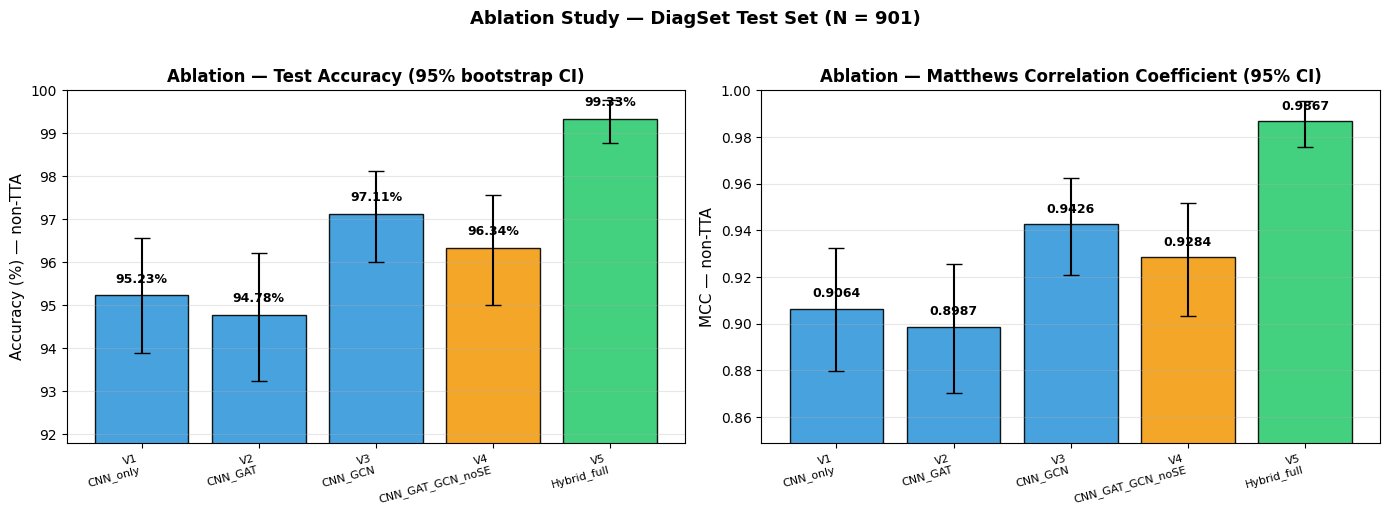

Saved figure: <repo>/results\Ablation\Ablation_Summary\ablation_summary_figure.png


In [11]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 9 — Ablation figure                                     ║
# ║   Accuracy (left) + MCC (right) with 95% bootstrap CIs        ║
# ║   V5 highlighted in green                                    ║
# ╚══════════════════════════════════════════════════════════════╝
print('=' * 60)
print('  STEP 6 — Ablation figure')
print('=' * 60)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

names = [r['variant'].replace('_', '\n', 1) for r in rows]
accs  = [r['acc_notta'] * 100 for r in rows]
acc_lo = [(r['acc_notta'] - r['acc_notta_lo']) * 100 for r in rows]
acc_hi = [(r['acc_notta_hi'] - r['acc_notta']) * 100 for r in rows]
mccs  = [r['mcc_notta'] for r in rows]
mcc_lo = [r['mcc_notta'] - r['mcc_notta_lo'] for r in rows]
mcc_hi = [r['mcc_notta_hi'] - r['mcc_notta'] for r in rows]

# Blue for V1-V3, orange for V4 (no-SE baseline), green for V5 (full model)
default_colors = ['#3498db', '#3498db', '#3498db', '#f39c12', '#2ecc71']
colors = default_colors[:len(rows)] if len(rows) <= 5 else ['#3498db'] * len(rows)

ax1.bar(range(len(rows)), accs, yerr=[acc_lo, acc_hi],
        color=colors, edgecolor='black', capsize=6, alpha=0.9)
ax1.set_xticks(range(len(rows)))
ax1.set_xticklabels(names, fontsize=8, rotation=15, ha='right')
ax1.set_ylabel('Accuracy (%) — non-TTA', fontsize=11)
ax1.set_title('Ablation — Test Accuracy (95% bootstrap CI)',
              fontsize=12, fontweight='bold')
ax1.grid(alpha=0.3, axis='y')
ax1.set_ylim([min(accs) - 3, 100])
for i, v in enumerate(accs):
    ax1.text(i, v + 0.3, f'{v:.2f}%', ha='center', fontsize=9, fontweight='bold')

ax2.bar(range(len(rows)), mccs, yerr=[mcc_lo, mcc_hi],
        color=colors, edgecolor='black', capsize=6, alpha=0.9)
ax2.set_xticks(range(len(rows)))
ax2.set_xticklabels(names, fontsize=8, rotation=15, ha='right')
ax2.set_ylabel('MCC — non-TTA', fontsize=11)
ax2.set_title('Ablation — Matthews Correlation Coefficient (95% CI)',
              fontsize=12, fontweight='bold')
ax2.grid(alpha=0.3, axis='y')
ax2.set_ylim([min(mccs) - 0.05, 1.0])
for i, v in enumerate(mccs):
    ax2.text(i, v + 0.005, f'{v:.4f}', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Ablation Study — DiagSet Test Set (N = 901)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_PATH, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved figure: {FIG_PATH}')


## CELL 10 — Final summary

In [12]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 10 — Final summary of everything produced               ║
# ╚══════════════════════════════════════════════════════════════╝
print('=' * 60)
print('  ABLATION AGGREGATOR — COMPLETE')
print('=' * 60)
print(f'  Ablation V5 folder: {WORK_DIR}')
print(f'    - v5_predictions.npz  (copy of hybrid_predictions.npz)')
print(f'    - README.txt          (documents Option A arrangement)')
print()
print(f'  Summary folder    : {OUT_DIR}')
print(f'    - ablation_summary.csv       (5-row full metrics table)')
print(f'    - ablation_summary_figure.png (dual bar chart, 300 DPI)')
print(f'    - ablation_report.txt         (paste-ready for Section 3)')
print(f'    - v4_vs_v5_mcnemar.txt        (SE-gate significance test)')
print('=' * 60)


  ABLATION AGGREGATOR — COMPLETE
  Ablation V5 folder: <repo>/results\Ablation\Ablation_V5
    - v5_predictions.npz  (copy of hybrid_predictions.npz)
    - README.txt          (documents Option A arrangement)

  Summary folder    : <repo>/results\Ablation\Ablation_Summary
    - ablation_summary.csv       (5-row full metrics table)
    - ablation_summary_figure.png (dual bar chart, 300 DPI)
    - ablation_report.txt         (paste-ready for Section 3)
    - v4_vs_v5_mcnemar.txt        (SE-gate significance test)
